In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Training Dataset.arff to Training Dataset.arff


In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
from scipy.io import arff

# Read the ARFF dataset
data, metadata = arff.loadarff('Training Dataset.arff')

# Convert ARFF data into Pandas DataFrame
df = pd.DataFrame(data)

# Convert byte values into strings if present
for column in df.select_dtypes(include=['object']).columns:
    df[column] = df[column].apply(
        lambda x: x.decode('utf-8') if isinstance(x, bytes) else x
    )

# Display first five records
print("First Five Records:")
display(df.head())

First Five Records:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [ ]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display target column distribution
print("\nTarget Column Distribution:")
print(df.iloc[:, -1].value_counts())

Dataset Shape: (11055, 31)

Column Names:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   having_IP_Address            11055 non-null  object
 1   URL_Length                   11055 non-null  object
 2   Shortining_Service           11055 non-null  object
 3   having_At_Symbol

In [ ]:
# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nTotal Duplicate Records:", df.duplicated().sum())

# Check target column distribution
print("\nTarget Class Distribution:")
print(df.iloc[:, -1].value_counts())

Missing Values in Each Column:
having_IP_Address              0
URL_Length                     0
Shortining_Service             0
having_At_Symbol               0
double_slash_redirecting       0
Prefix_Suffix                  0
having_Sub_Domain              0
SSLfinal_State                 0
Domain_registeration_length    0
Favicon                        0
port                           0
HTTPS_token                    0
Request_URL                    0
URL_of_Anchor                  0
Links_in_tags                  0
SFH                            0
Submitting_to_email            0
Abnormal_URL                   0
Redirect                       0
on_mouseover                   0
RightClick                     0
popUpWidnow                    0
Iframe                         0
age_of_domain                  0
DNSRecord                      0
web_traffic                    0
Page_Rank                      0
Google_Index                   0
Links_pointing_to_page         0
Statistical_

In [ ]:
# Dataset cleaning summary

print("Total Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Records:", df.duplicated().sum())

print("\nTarget Class Distribution:")
print(df.iloc[:, -1].value_counts())

print("\nDataset Shape:", df.shape)

Total Missing Values: 0
Total Duplicate Records: 5206

Target Class Distribution:
Result
1     6157
-1    4898
Name: count, dtype: int64

Dataset Shape: (11055, 31)


In [ ]:
# Separate features and target
feature_columns = df.columns[:-1]
target_column = df.columns[-1]

# Check duplicate feature combinations
feature_duplicates = df.duplicated(
    subset=feature_columns
).sum()

# Check whether identical features have conflicting labels
label_counts = df.groupby(
    list(feature_columns),
    dropna=False
)[target_column].nunique()

conflicting_labels = (label_counts > 1).sum()

print("Duplicate Feature Records:", feature_duplicates)

print("Feature Combinations with Conflicting Labels:",
      conflicting_labels)

# Check exact duplicate records
print("Exact Duplicate Records:", df.duplicated().sum())

Duplicate Feature Records: 5270
Feature Combinations with Conflicting Labels: 64
Exact Duplicate Records: 5206


In [ ]:
# Identify feature columns and target column
feature_columns = df.columns[:-1]
target_column = df.columns[-1]

# Find feature combinations having conflicting labels
label_counts = df.groupby(
    list(feature_columns)
)[target_column].nunique()

conflicting_features = label_counts[label_counts > 1].index

# Remove ambiguous feature combinations
df_clean = df.set_index(
    list(feature_columns)
).drop(index=conflicting_features).reset_index()

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

# Display cleaning results
print("Original Dataset Shape:", df.shape)

print("Cleaned Dataset Shape:", df_clean.shape)

print("Remaining Duplicate Records:",
      df_clean.duplicated().sum())

print("Remaining Missing Values:",
      df_clean.isnull().sum().sum())

print("\nTarget Distribution:")
print(df_clean[target_column].value_counts())

Original Dataset Shape: (11055, 31)
Cleaned Dataset Shape: (5721, 31)
Remaining Duplicate Records: 0
Remaining Missing Values: 0

Target Distribution:
Result
-1    2955
1     2766
Name: count, dtype: int64


In [ ]:
# Create a copy of the cleaned dataset
df_model = df_clean.copy()

# Convert all columns into numeric format
for column in df_model.columns:
    df_model[column] = pd.to_numeric(
        df_model[column],
        errors='coerce'
    )

# Check data types after conversion
print("Data Types After Conversion:")
print(df_model.dtypes)

# Check missing values after conversion
print("\nMissing Values After Conversion:")
print(df_model.isnull().sum().sum())

# Display first five records
print("\nFirst Five Records:")
display(df_model.head())

Data Types After Conversion:
having_IP_Address              int64
URL_Length                     int64
Shortining_Service             int64
having_At_Symbol               int64
double_slash_redirecting       int64
Prefix_Suffix                  int64
having_Sub_Domain              int64
SSLfinal_State                 int64
Domain_registeration_length    int64
Favicon                        int64
port                           int64
HTTPS_token                    int64
Request_URL                    int64
URL_of_Anchor                  int64
Links_in_tags                  int64
SFH                            int64
Submitting_to_email            int64
Abnormal_URL                   int64
Redirect                       int64
on_mouseover                   int64
RightClick                     int64
popUpWidnow                    int64
Iframe                         int64
age_of_domain                  int64
DNSRecord                      int64
web_traffic                    int64
Page_Rank

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [ ]:
# Check numerical data types
print("Data Type Summary:")
print(df_model.dtypes.value_counts())

# Check missing values
print("\nTotal Missing Values:",
      df_model.isnull().sum().sum())

# Check dataset shape
print("\nDataset Shape:", df_model.shape)

# Check target column
print("\nTarget Column:", df_model.columns[-1])

# Display target values
print("\nTarget Values:")
print(df_model.iloc[:, -1].value_counts())

Data Type Summary:
int64    31
Name: count, dtype: int64

Total Missing Values: 0

Dataset Shape: (5721, 31)

Target Column: Result

Target Values:
Result
-1    2955
 1    2766
Name: count, dtype: int64


In [ ]:
# Separate input features (X) and target (y)

X = df_model.drop('Result', axis=1)

y = df_model['Result'].map({
    -1: 1,
     1: 0
})

# Display feature information
print("Input Features (X):")
print(X.shape)

print("\nTarget Variable (y):")
print(y.shape)

# Display target distribution
print("\nTarget Class Distribution:")
print(y.value_counts())

print("\nTarget Label Meaning:")
print("1 = Phishing Website")
print("0 = Legitimate Website")

# Display first five feature records
print("\nFirst Five Input Records:")
display(X.head())

Input Features (X):
(5721, 30)

Target Variable (y):
(5721,)

Target Class Distribution:
Result
1    2955
0    2766
Name: count, dtype: int64

Target Label Meaning:
1 = Phishing Website
0 = Legitimate Website

First Five Input Records:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


In [ ]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Display class distribution
print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data Shape: (4576, 30)
Testing Data Shape: (1145, 30)

Training Target Shape: (4576,)
Testing Target Shape: (1145,)

Training Class Distribution:
Result
1    2364
0    2212
Name: count, dtype: int64

Testing Class Distribution:
Result
1    591
0    554
Name: count, dtype: int64


In [ ]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create StandardScaler object
scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

# Display results
print("Original Training Data Shape:", X_train.shape)

print("Scaled Training Data Shape:", X_train_scaled.shape)

print("\nOriginal Testing Data Shape:", X_test.shape)

print("Scaled Testing Data Shape:", X_test_scaled.shape)

print("\nFeature Scaling Completed Successfully!")

Original Training Data Shape: (4576, 30)
Scaled Training Data Shape: (4576, 30)

Original Testing Data Shape: (1145, 30)
Scaled Testing Data Shape: (1145, 30)

Feature Scaling Completed Successfully!


In [ ]:
# Import required evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Create dictionary to store model results
results = {}

print("Evaluation libraries imported successfully!")
print("Results dictionary created!")

Evaluation libraries imported successfully!
Results dictionary created!


In [ ]:
# Import KNN algorithm
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN Model Training Completed Successfully!")

KNN Model Training Completed Successfully!


In [ ]:
# Predict website classes
y_pred_knn = knn_model.predict(X_test_scaled)

# Display first 20 predictions
print("First 20 KNN Predictions:")
print(y_pred_knn[:20])

print("\nActual Target Values:")
print(y_test.values[:20])

First 20 KNN Predictions:
[1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0]

Actual Target Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate evaluation metrics

knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(y_test, y_pred_knn)

knn_recall = recall_score(y_test, y_pred_knn)

knn_f1 = f1_score(y_test, y_pred_knn)

# Store results
results["KNN"] = {
    "Accuracy": knn_accuracy,
    "Precision": knn_precision,
    "Recall": knn_recall,
    "F1-Score": knn_f1
}

# Display results
print("KNN PERFORMANCE RESULTS")

print("Accuracy:", round(knn_accuracy * 100, 2), "%")
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1-Score:", round(knn_f1, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["Legitimate", "Phishing"]
))

KNN PERFORMANCE RESULTS
Accuracy: 92.4 %
Precision: 0.9172
Recall: 0.9374
F1-Score: 0.9272

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.93      0.91      0.92       554
    Phishing       0.92      0.94      0.93       591

    accuracy                           0.92      1145
   macro avg       0.92      0.92      0.92      1145
weighted avg       0.92      0.92      0.92      1145



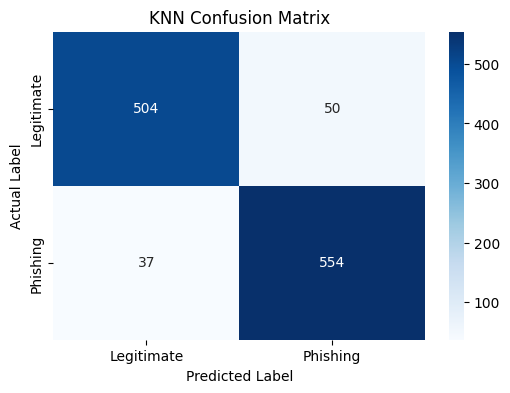

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
print("KNN Algorithm Results")

print("Accuracy:",
      round(results["KNN"]["Accuracy"] * 100, 2), "%")

print("Precision:",
      round(results["KNN"]["Precision"], 4))

print("Recall:",
      round(results["KNN"]["Recall"], 4))

print("F1-Score:",
      round(results["KNN"]["F1-Score"], 4))

KNN Algorithm Results
Accuracy: 92.4 %
Precision: 0.9172
Recall: 0.9374
F1-Score: 0.9272


In [ ]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


In [ ]:
# Predict using Logistic Regression
y_pred_lr = lr_model.predict(X_test_scaled)

# Display first 20 predictions
print("First 20 Predictions:")
print(y_pred_lr[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 Predictions:
[1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate performance metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(y_test, y_pred_lr)

lr_recall = recall_score(y_test, y_pred_lr)

lr_f1 = f1_score(y_test, y_pred_lr)

# Store results
results["Logistic Regression"] = {
    "Accuracy": lr_accuracy,
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1-Score": lr_f1
}

# Display results
print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision, 4))
print("Recall:", round(lr_recall, 4))
print("F1-Score:", round(lr_f1, 4))

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Legitimate", "Phishing"]
))

LOGISTIC REGRESSION RESULTS
Accuracy: 91.27 %
Precision: 0.9182
Recall: 0.912
F1-Score: 0.9151

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.91      0.91      0.91       554
    Phishing       0.92      0.91      0.92       591

    accuracy                           0.91      1145
   macro avg       0.91      0.91      0.91      1145
weighted avg       0.91      0.91      0.91      1145



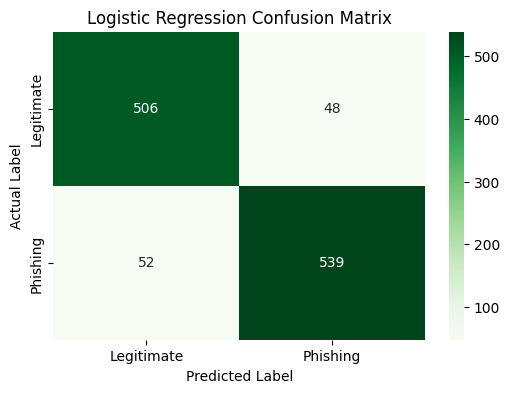

In [ ]:
# Generate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import Artificial Neural Network
from sklearn.neural_network import MLPClassifier

# Create ANN model
ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42,
    early_stopping=True
)

print("ANN Model Created Successfully!")

ANN Model Created Successfully!


In [ ]:
# Train ANN model
ann_model.fit(X_train_scaled, y_train)

print("ANN Model Training Completed Successfully!")

ANN Model Training Completed Successfully!


In [ ]:
# Predict website classification
y_pred_ann = ann_model.predict(X_test_scaled)

print("First 20 ANN Predictions:")
print(y_pred_ann[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 ANN Predictions:
[1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 0 1 1 1 0]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate performance metrics
ann_accuracy = accuracy_score(y_test, y_pred_ann)

ann_precision = precision_score(y_test, y_pred_ann)

ann_recall = recall_score(y_test, y_pred_ann)

ann_f1 = f1_score(y_test, y_pred_ann)

# Store results
results["ANN"] = {
    "Accuracy": ann_accuracy,
    "Precision": ann_precision,
    "Recall": ann_recall,
    "F1-Score": ann_f1
}

# Display performance
print("ANN PERFORMANCE RESULTS")

print("Accuracy:", round(ann_accuracy * 100, 2), "%")
print("Precision:", round(ann_precision, 4))
print("Recall:", round(ann_recall, 4))
print("F1-Score:", round(ann_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_ann,
    target_names=["Legitimate", "Phishing"]
))

ANN PERFORMANCE RESULTS
Accuracy: 93.45 %
Precision: 0.9403
Recall: 0.9323
F1-Score: 0.9363

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.93      0.94      0.93       554
    Phishing       0.94      0.93      0.94       591

    accuracy                           0.93      1145
   macro avg       0.93      0.93      0.93      1145
weighted avg       0.93      0.93      0.93      1145



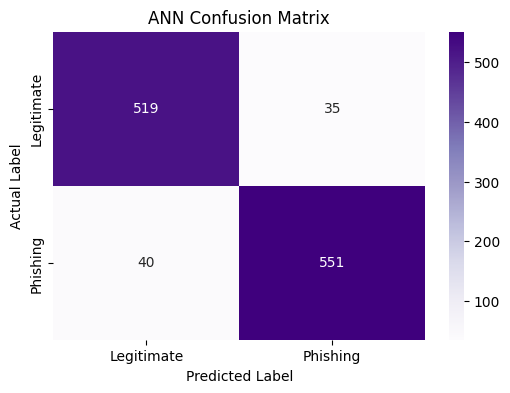

In [ ]:
# Generate confusion matrix
cm_ann = confusion_matrix(y_test, y_pred_ann)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import Support Vector Machine
from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    random_state=42
)

print("SVM Model Created Successfully!")

SVM Model Created Successfully!


In [ ]:
# Train the SVM model
svm_model.fit(X_train_scaled, y_train)

print("SVM Model Training Completed Successfully!")

SVM Model Training Completed Successfully!


In [ ]:
# Predict website classification
y_pred_svm = svm_model.predict(X_test_scaled)

print("First 20 SVM Predictions:")
print(y_pred_svm[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 SVM Predictions:
[1 1 1 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(y_test, y_pred_svm)

svm_recall = recall_score(y_test, y_pred_svm)

svm_f1 = f1_score(y_test, y_pred_svm)

# Store results
results["SVM"] = {
    "Accuracy": svm_accuracy,
    "Precision": svm_precision,
    "Recall": svm_recall,
    "F1-Score": svm_f1
}

# Display performance
print("SVM PERFORMANCE RESULTS")

print("Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Precision:", round(svm_precision, 4))
print("Recall:", round(svm_recall, 4))
print("F1-Score:", round(svm_f1, 4))

# Classification report
print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Legitimate", "Phishing"]
))

SVM PERFORMANCE RESULTS
Accuracy: 93.97 %
Precision: 0.9531
Recall: 0.9289
F1-Score: 0.9409

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.93      0.95      0.94       554
    Phishing       0.95      0.93      0.94       591

    accuracy                           0.94      1145
   macro avg       0.94      0.94      0.94      1145
weighted avg       0.94      0.94      0.94      1145



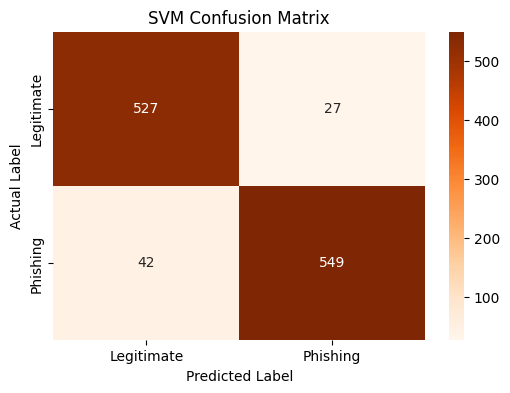

In [ ]:
# Generate confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Create model
nb_model = GaussianNB()

print("Naive Bayes Model Created Successfully!")

Naive Bayes Model Created Successfully!


In [ ]:
# Train Naive Bayes
nb_model.fit(X_train_scaled, y_train)

print("Naive Bayes Training Completed Successfully!")

Naive Bayes Training Completed Successfully!


In [ ]:
# Predict website classification
y_pred_nb = nb_model.predict(X_test_scaled)

print("First 20 Predictions:")
print(y_pred_nb[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 Predictions:
[1 1 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(y_test, y_pred_nb)

nb_recall = recall_score(y_test, y_pred_nb)

nb_f1 = f1_score(y_test, y_pred_nb)

# Store results
results["Naive Bayes"] = {
    "Accuracy": nb_accuracy,
    "Precision": nb_precision,
    "Recall": nb_recall,
    "F1-Score": nb_f1
}

# Display results
print("NAIVE BAYES PERFORMANCE")

print("Accuracy:", round(nb_accuracy * 100, 2), "%")
print("Precision:", round(nb_precision, 4))
print("Recall:", round(nb_recall, 4))
print("F1-Score:", round(nb_f1, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Legitimate", "Phishing"]
))

NAIVE BAYES PERFORMANCE
Accuracy: 64.98 %
Precision: 0.5958
Recall: 1.0
F1-Score: 0.7467

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.28      0.43       554
    Phishing       0.60      1.00      0.75       591

    accuracy                           0.65      1145
   macro avg       0.80      0.64      0.59      1145
weighted avg       0.79      0.65      0.59      1145



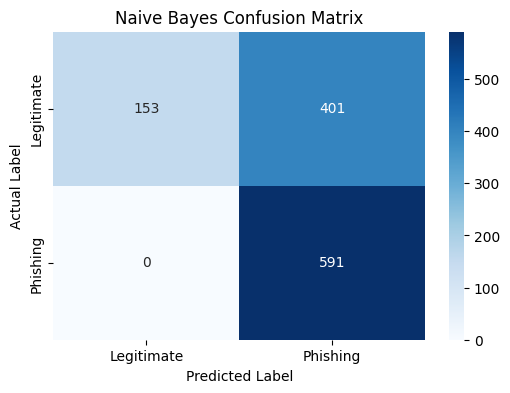

In [ ]:
# Generate confusion matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=10,
    random_state=42
)

print("Decision Tree Model Created Successfully!")

Decision Tree Model Created Successfully!


In [ ]:
# Train Decision Tree
dt_model.fit(X_train, y_train)

print("Decision Tree Training Completed Successfully!")

Decision Tree Training Completed Successfully!


In [ ]:
# Predict website classification
y_pred_dt = dt_model.predict(X_test)

print("First 20 Predictions:")
print(y_pred_dt[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 Predictions:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 1 1 0]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(y_test, y_pred_dt)

dt_recall = recall_score(y_test, y_pred_dt)

dt_f1 = f1_score(y_test, y_pred_dt)

# Store results
results["Decision Tree"] = {
    "Accuracy": dt_accuracy,
    "Precision": dt_precision,
    "Recall": dt_recall,
    "F1-Score": dt_f1
}

# Display results
print("DECISION TREE PERFORMANCE")

print("Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Precision:", round(dt_precision, 4))
print("Recall:", round(dt_recall, 4))
print("F1-Score:", round(dt_f1, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Legitimate", "Phishing"]
))

DECISION TREE PERFORMANCE
Accuracy: 93.97 %
Precision: 0.9424
Recall: 0.9408
F1-Score: 0.9416

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.94      0.94      0.94       554
    Phishing       0.94      0.94      0.94       591

    accuracy                           0.94      1145
   macro avg       0.94      0.94      0.94      1145
weighted avg       0.94      0.94      0.94      1145



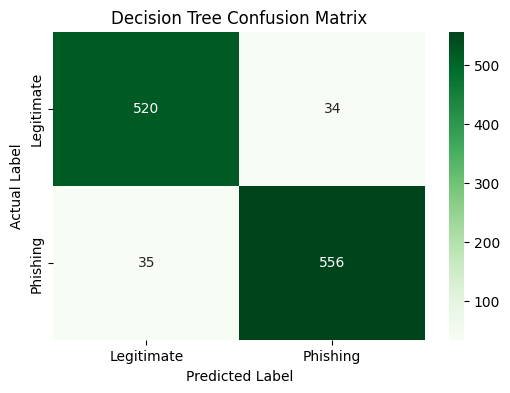

In [ ]:
# Generate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

print("Random Forest Model Created Successfully!")

Random Forest Model Created Successfully!


In [ ]:
# Train Random Forest model
rf_model.fit(X_train, y_train)

print("Random Forest Training Completed Successfully!")

Random Forest Training Completed Successfully!


In [ ]:
# Predict website classification
y_pred_rf = rf_model.predict(X_test)

print("First 20 Predictions:")
print(y_pred_rf[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 Predictions:
[1 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 1 1 0]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(y_test, y_pred_rf)

rf_recall = recall_score(y_test, y_pred_rf)

rf_f1 = f1_score(y_test, y_pred_rf)

# Store results
results["Random Forest"] = {
    "Accuracy": rf_accuracy,
    "Precision": rf_precision,
    "Recall": rf_recall,
    "F1-Score": rf_f1
}

# Display performance
print("RANDOM FOREST PERFORMANCE")

print("Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-Score:", round(rf_f1, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Legitimate", "Phishing"]
))

RANDOM FOREST PERFORMANCE
Accuracy: 95.2 %
Precision: 0.9669
Recall: 0.9391
F1-Score: 0.9528

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.94      0.97      0.95       554
    Phishing       0.97      0.94      0.95       591

    accuracy                           0.95      1145
   macro avg       0.95      0.95      0.95      1145
weighted avg       0.95      0.95      0.95      1145



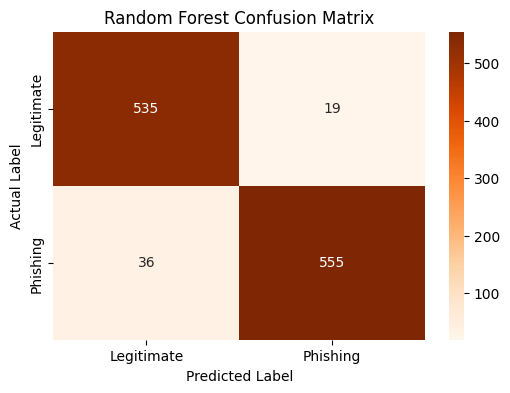

In [ ]:
# Generate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

print("Gradient Boosting Model Created Successfully!")

Gradient Boosting Model Created Successfully!


In [ ]:
# Train Gradient Boosting model
gb_model.fit(X_train, y_train)

print("Gradient Boosting Training Completed Successfully!")

Gradient Boosting Training Completed Successfully!


In [ ]:
# Predict website classification
y_pred_gb = gb_model.predict(X_test)

print("First 20 Predictions:")
print(y_pred_gb[:20])

print("\nActual Values:")
print(y_test.values[:20])

First 20 Predictions:
[1 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 1 1 0]

Actual Values:
[0 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 1 1 1 0]


In [ ]:
# Calculate evaluation metrics
gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(y_test, y_pred_gb)

gb_recall = recall_score(y_test, y_pred_gb)

gb_f1 = f1_score(y_test, y_pred_gb)

# Store results
results["Gradient Boosting"] = {
    "Accuracy": gb_accuracy,
    "Precision": gb_precision,
    "Recall": gb_recall,
    "F1-Score": gb_f1
}

# Display results
print("GRADIENT BOOSTING PERFORMANCE")

print("Accuracy:", round(gb_accuracy * 100, 2), "%")
print("Precision:", round(gb_precision, 4))
print("Recall:", round(gb_recall, 4))
print("F1-Score:", round(gb_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    target_names=["Legitimate", "Phishing"]
))

GRADIENT BOOSTING PERFORMANCE
Accuracy: 95.28 %
Precision: 0.9605
Recall: 0.9475
F1-Score: 0.954

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.94      0.96      0.95       554
    Phishing       0.96      0.95      0.95       591

    accuracy                           0.95      1145
   macro avg       0.95      0.95      0.95      1145
weighted avg       0.95      0.95      0.95      1145



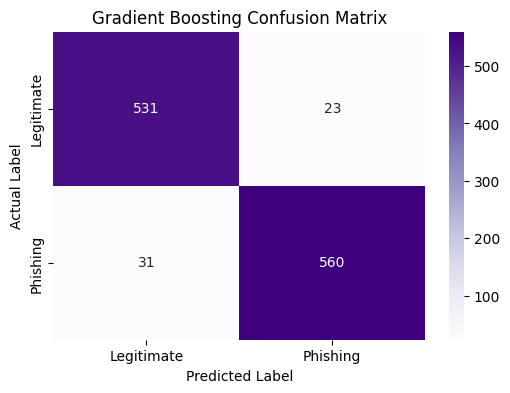

In [ ]:
# Generate confusion matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
# Import CNN libraries
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout
)

print("CNN Libraries Imported Successfully!")

CNN Libraries Imported Successfully!


In [ ]:
# Reshape training and testing data
X_train_cnn = X_train_scaled.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

X_test_cnn = X_test_scaled.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

print("CNN Training Shape:", X_train_cnn.shape)
print("CNN Testing Shape:", X_test_cnn.shape)

print("CNN Data Reshaping Completed!")

CNN Training Shape: (4576, 30, 1)
CNN Testing Shape: (1145, 30, 1)
CNN Data Reshaping Completed!


In [ ]:
# Create CNN model
cnn_model = Sequential([

    Conv1D(
        filters=64,
        kernel_size=3,
        activation='relu',
        input_shape=(30, 1)
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation='relu'
    ),

    Flatten(),

    Dense(64, activation='relu'),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

# Display model architecture
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 28, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 12, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,137 (121.63 KB)

 Trainable params: 31,137 (121.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile CNN model
cnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train CNN model
cnn_history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("CNN Training Completed Successfully!")

Epoch 1/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.8740 - loss: 0.3189 - val_accuracy: 0.9367 - val_loss: 0.1663
Epoch 2/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9314 - loss: 0.1893 - val_accuracy: 0.9356 - val_loss: 0.1562
Epoch 3/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.9347 - loss: 0.1652 - val_accuracy: 0.9454 - val_loss: 0.1335
Epoch 4/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9374 - loss: 0.1554 - val_accuracy: 0.9443 - val_loss: 0.1303
Epoch 5/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9443 - loss: 0.1427 - val_accuracy: 0.9378 - val_loss: 0.1434
Epoch 6/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9462 - loss: 0.1369 - val_accuracy: 0.9487 - val_loss: 0.1212
Epoch 7/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9505 - loss: 0.1280 - val_accuracy: 0.9531 - val_loss: 0.1137
Epoch 8/30
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9459 - loss: 0.1234 - val_accura

In [ ]:
# Generate predictions
cnn_probabilities = cnn_model.predict(X_test_cnn)

# Convert probabilities into class labels
y_pred_cnn = (
    cnn_probabilities.ravel() >= 0.5
).astype(int)

# Calculate performance metrics
cnn_accuracy = accuracy_score(y_test, y_pred_cnn)

cnn_precision = precision_score(y_test, y_pred_cnn)

cnn_recall = recall_score(y_test, y_pred_cnn)

cnn_f1 = f1_score(y_test, y_pred_cnn)

# Store results
results["CNN"] = {
    "Accuracy": cnn_accuracy,
    "Precision": cnn_precision,
    "Recall": cnn_recall,
    "F1-Score": cnn_f1
}

# Display results
print("CNN PERFORMANCE RESULTS")

print("Accuracy:", round(cnn_accuracy * 100, 2), "%")
print("Precision:", round(cnn_precision, 4))
print("Recall:", round(cnn_recall, 4))
print("F1-Score:", round(cnn_f1, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_cnn,
    target_names=["Legitimate", "Phishing"]
))

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
CNN PERFORMANCE RESULTS
Accuracy: 95.2 %
Precision: 0.9702
Recall: 0.9357
F1-Score: 0.9526

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.93      0.97      0.95       554
    Phishing       0.97      0.94      0.95       591

    accuracy                           0.95      1145
   macro avg       0.95      0.95      0.95      1145
weighted avg       0.95      0.95      0.95      1145



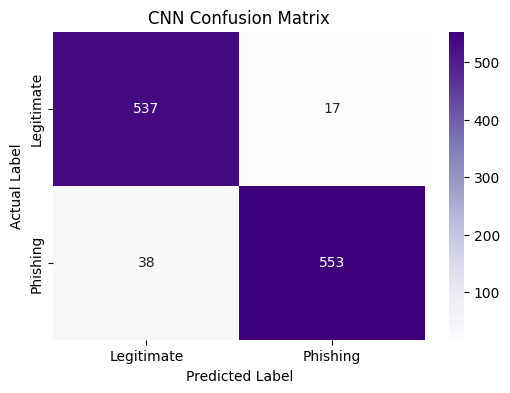

In [ ]:
# Generate confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_cnn,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
from sklearn.ensemble import VotingClassifier

print("Voting Classifier Imported Successfully!")

Voting Classifier Imported Successfully!


In [ ]:
# Create Ensemble Voting Classifier

ensemble_model = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(max_iter=1000)),
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('dt', DecisionTreeClassifier(random_state=42)),
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('svm', SVC(kernel='rbf', probability=True, random_state=42))
    ],
    voting='soft'
)

print("Ensemble Model Created Successfully!")

Ensemble Model Created Successfully!


In [ ]:
ensemble_model.fit(X_train_scaled, y_train)

print("Ensemble Model Training Completed!")

Ensemble Model Training Completed!


In [ ]:
y_pred_ensemble = ensemble_model.predict(X_test_scaled)

print("Ensemble Predictions Generated Successfully!")

Ensemble Predictions Generated Successfully!


In [ ]:
ensemble_accuracy = accuracy_score(y_test, y_pred_ensemble)

ensemble_precision = precision_score(y_test, y_pred_ensemble)

ensemble_recall = recall_score(y_test, y_pred_ensemble)

ensemble_f1 = f1_score(y_test, y_pred_ensemble)

results["Ensemble Learning"] = {
    "Accuracy": ensemble_accuracy,
    "Precision": ensemble_precision,
    "Recall": ensemble_recall,
    "F1-Score": ensemble_f1
}

print("ENSEMBLE LEARNING RESULTS")

print("Accuracy:", round(ensemble_accuracy * 100, 2), "%")
print("Precision:", round(ensemble_precision, 4))
print("Recall:", round(ensemble_recall, 4))
print("F1-Score:", round(ensemble_f1, 4))

print(classification_report(
    y_test,
    y_pred_ensemble,
    target_names=["Legitimate", "Phishing"]
))

ENSEMBLE LEARNING RESULTS
Accuracy: 95.2 %
Precision: 0.9605
Recall: 0.9459
F1-Score: 0.9531
              precision    recall  f1-score   support

  Legitimate       0.94      0.96      0.95       554
    Phishing       0.96      0.95      0.95       591

    accuracy                           0.95      1145
   macro avg       0.95      0.95      0.95      1145
weighted avg       0.95      0.95      0.95      1145



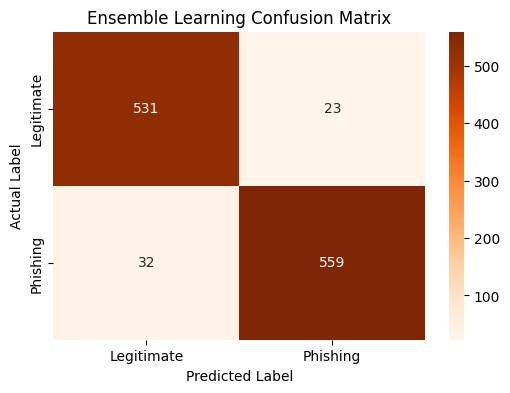

In [ ]:
cm_ensemble = confusion_matrix(y_test, y_pred_ensemble)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_ensemble,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Ensemble Learning Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
import pandas as pd

# Convert results dictionary into DataFrame

comparison_df = pd.DataFrame(results).T

# Convert metrics into percentage

comparison_df = comparison_df * 100

# Round values

comparison_df = comparison_df.round(2)

print("FINAL COMPARISON OF ALL 10 ALGORITHMS")

display(comparison_df)

FINAL COMPARISON OF ALL 10 ALGORITHMS


,Accuracy,Precision,Recall,F1-Score
KNN,92.40,91.72,93.74,92.72
Logistic Regression,91.27,91.82,91.20,91.51
ANN,93.45,94.03,93.23,93.63
SVM,93.97,95.31,92.89,94.09
Naive Bayes,64.98,59.58,100.00,74.67
Decision Tree,93.97,94.24,94.08,94.16
Random Forest,95.20,96.69,93.91,95.28
Gradient Boosting,95.28,96.05,94.75,95.40
CNN,95.20,97.02,93.57,95.26
Ensemble Learning,95.20,96.05,94.59,95.31


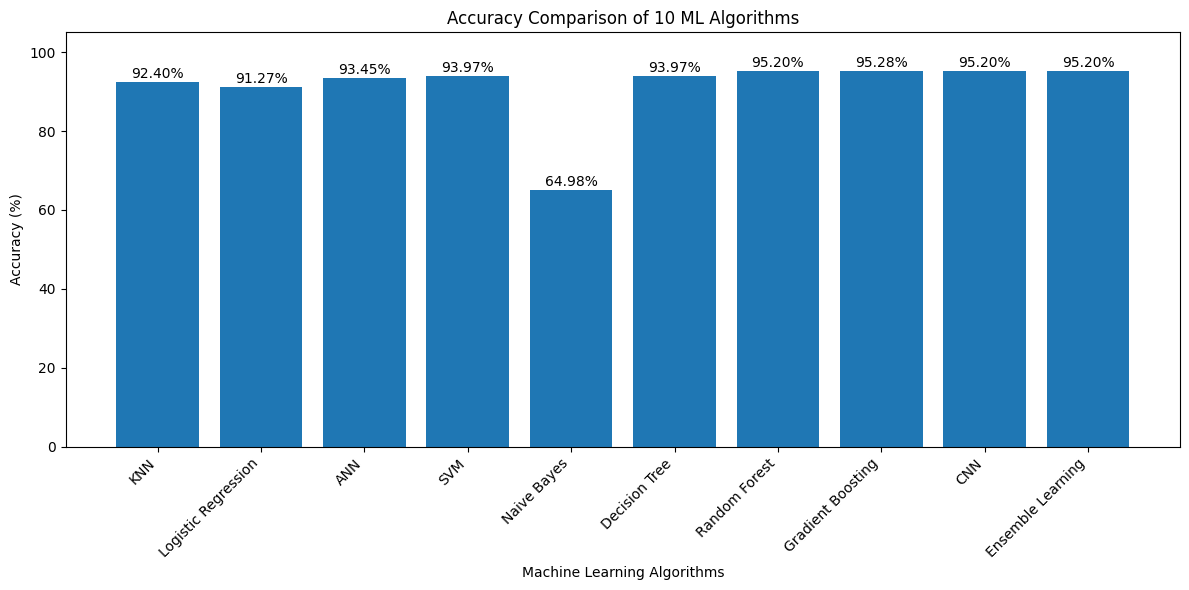

In [ ]:
plt.figure(figsize=(12, 6))

accuracy_values = comparison_df["Accuracy"]

plt.bar(
    accuracy_values.index,
    accuracy_values.values
)

plt.title("Accuracy Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=45, ha="right")

plt.ylim(0, 105)

for i, value in enumerate(accuracy_values):
    plt.text(i, value + 1, f"{value:.2f}%",
             ha="center")

plt.tight_layout()
plt.show()

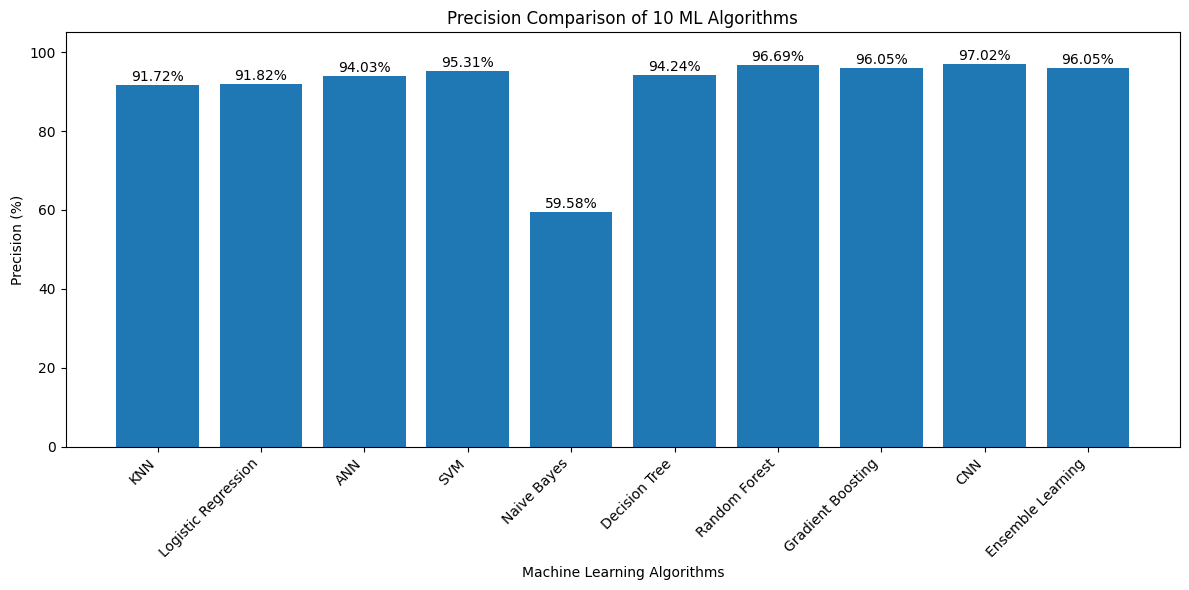

In [ ]:
plt.figure(figsize=(12, 6))

precision_values = comparison_df["Precision"]

plt.bar(
    precision_values.index,
    precision_values.values
)

plt.title("Precision Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Precision (%)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 105)

for i, value in enumerate(precision_values):
    plt.text(i, value + 1, f"{value:.2f}%",
             ha="center")

plt.tight_layout()
plt.show()

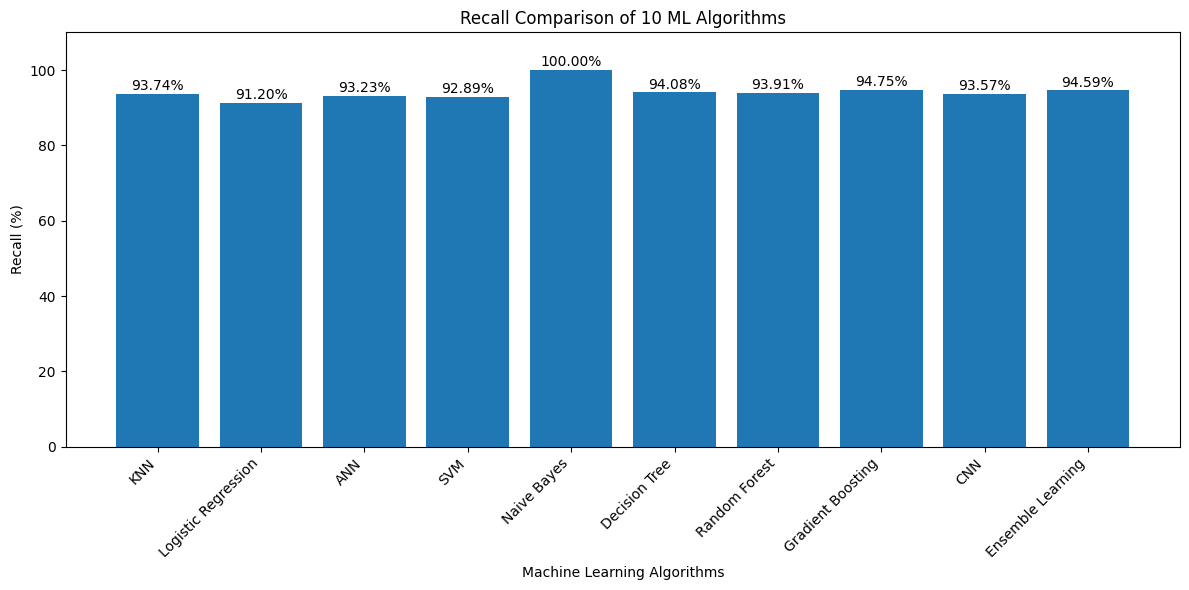

In [ ]:
plt.figure(figsize=(12, 6))

recall_values = comparison_df["Recall"]

plt.bar(
    recall_values.index,
    recall_values.values
)

plt.title("Recall Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Recall (%)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 110)

for i, value in enumerate(recall_values):
    plt.text(i, value + 1, f"{value:.2f}%",
             ha="center")

plt.tight_layout()
plt.show()

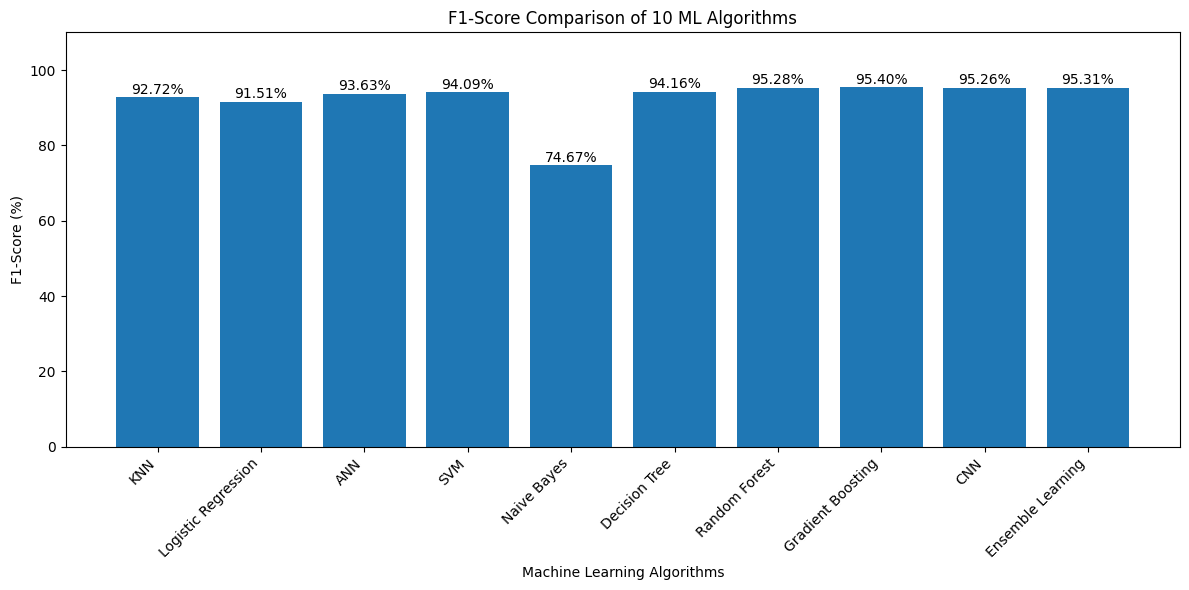

In [ ]:
plt.figure(figsize=(12, 6))

f1_values = comparison_df["F1-Score"]

plt.bar(f1_values.index, f1_values.values)

plt.title("F1-Score Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("F1-Score (%)")

plt.xticks(rotation=45, ha="right")
plt.ylim(0, 110)

for i, value in enumerate(f1_values):
    plt.text(i, value + 1, f"{value:.2f}%",
             ha="center")

plt.tight_layout()
plt.show()

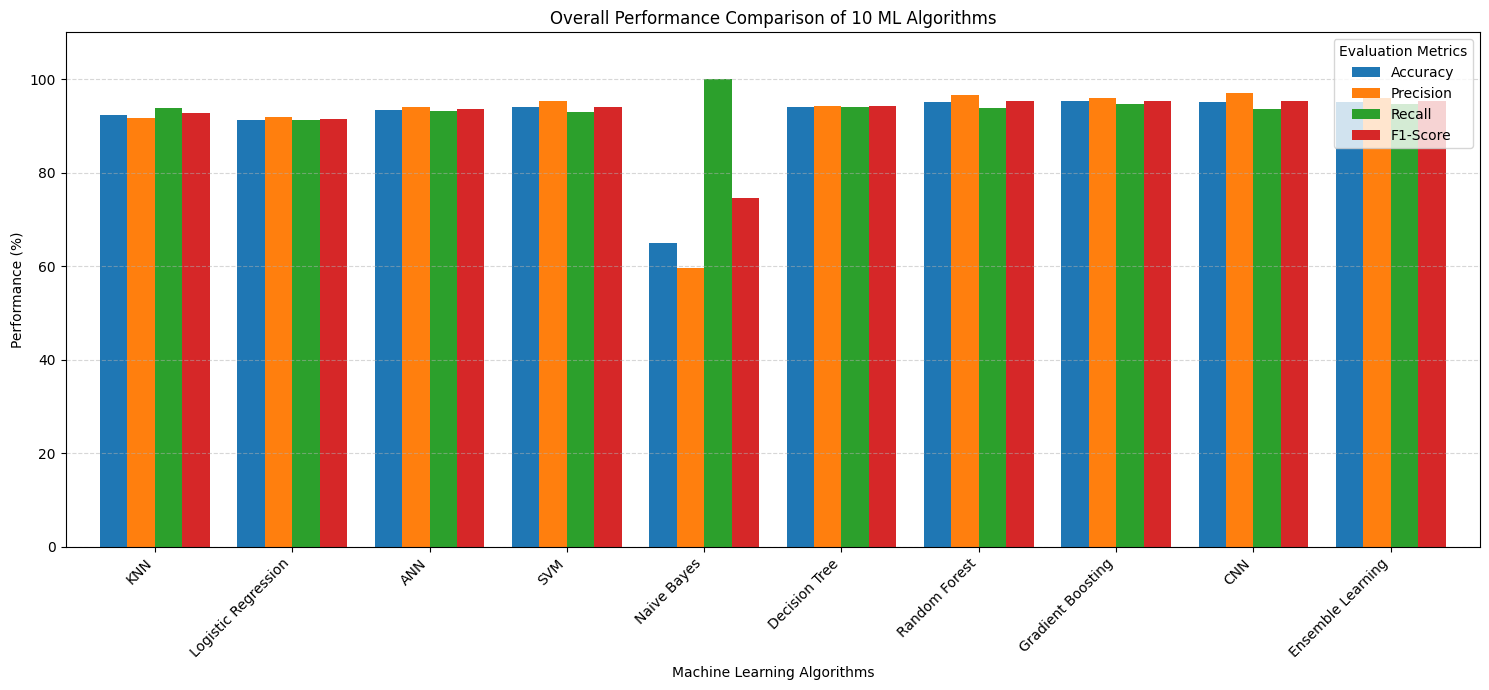

In [ ]:
comparison_df.plot(
    kind='bar',
    figsize=(15, 7),
    width=0.8
)

plt.title("Overall Performance Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Performance (%)")

plt.xticks(rotation=45, ha='right')
plt.ylim(0, 110)

plt.legend(title="Evaluation Metrics")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
ranking_df = comparison_df.sort_values(
    by="F1-Score",
    ascending=False
)

print("FINAL RANKING OF 10 ML ALGORITHMS")

display(ranking_df)

FINAL RANKING OF 10 ML ALGORITHMS


,Accuracy,Precision,Recall,F1-Score
Gradient Boosting,95.28,96.05,94.75,95.40
Ensemble Learning,95.20,96.05,94.59,95.31
Random Forest,95.20,96.69,93.91,95.28
CNN,95.20,97.02,93.57,95.26
Decision Tree,93.97,94.24,94.08,94.16
SVM,93.97,95.31,92.89,94.09
ANN,93.45,94.03,93.23,93.63
KNN,92.40,91.72,93.74,92.72
Logistic Regression,91.27,91.82,91.20,91.51
Naive Bayes,64.98,59.58,100.00,74.67


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


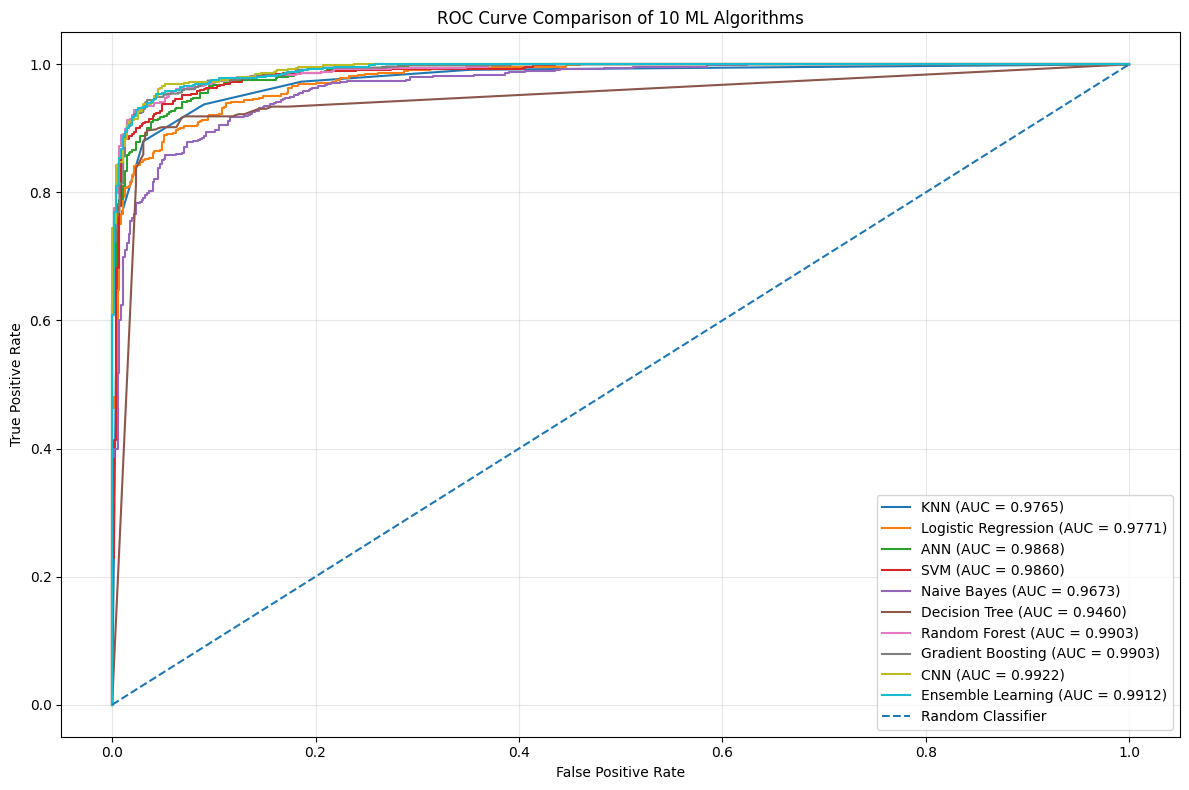

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Store ROC results
roc_results = {}

# Function to get prediction probabilities
def get_scores(model, X):

    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]

    elif hasattr(model, "decision_function"):
        return model.decision_function(X)

    else:
        raise ValueError("Model does not support ROC scores")


# Define models
roc_models = {
    "KNN": (knn_model, X_test_scaled),
    "Logistic Regression": (lr_model, X_test_scaled),
    "ANN": (ann_model, X_test_scaled),
    "SVM": (svm_model, X_test_scaled),
    "Naive Bayes": (nb_model, X_test_scaled),
    "Decision Tree": (dt_model, X_test_scaled),
    "Random Forest": (rf_model, X_test_scaled),
    "Gradient Boosting": (gb_model, X_test_scaled),
    "CNN": (cnn_model, X_test_cnn),
    "Ensemble Learning": (ensemble_model, X_test_scaled)
}


# Calculate ROC and AUC
plt.figure(figsize=(12, 8))

for name, (model, X_data) in roc_models.items():

    if name == "CNN":
        scores = cnn_model.predict(
            X_test_cnn, verbose=0
        ).ravel()

    else:
        scores = get_scores(model, X_data)

    fpr, tpr, thresholds = roc_curve(y_test, scores)

    roc_auc = auc(fpr, tpr)

    roc_results[name] = roc_auc

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )


# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison of 10 ML Algorithms")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Create AUC comparison table
auc_df = pd.DataFrame(
    list(roc_results.items()),
    columns=["Algorithm", "AUC Score"]
)

# Sort algorithms by AUC
auc_df = auc_df.sort_values(
    by="AUC Score",
    ascending=False
).reset_index(drop=True)

# Display ranking
auc_df.index = auc_df.index + 1

print("FINAL AUC COMPARISON OF 10 ML ALGORITHMS")

display(auc_df.style.format({
    "AUC Score": "{:.4f}"
}))

FINAL AUC COMPARISON OF 10 ML ALGORITHMS


,Algorithm,AUC Score
1,CNN,0.9922
2,Ensemble Learning,0.9912
3,Gradient Boosting,0.9903
4,Random Forest,0.9903
5,ANN,0.9868
6,SVM,0.9860
7,Logistic Regression,0.9771
8,KNN,0.9765
9,Naive Bayes,0.9673
10,Decision Tree,0.9460


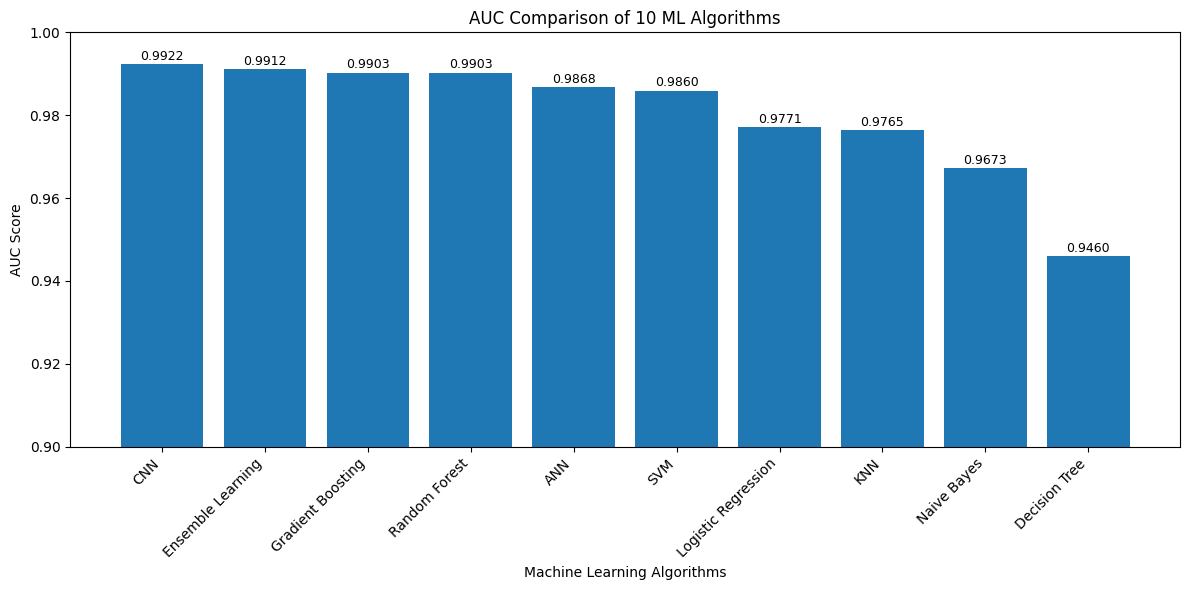

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    auc_df["Algorithm"],
    auc_df["AUC Score"]
)

plt.title("AUC Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("AUC Score")

plt.ylim(0.90, 1.00)
plt.xticks(rotation=45, ha="right")

for i, value in enumerate(auc_df["AUC Score"]):
    plt.text(i, value + 0.001, f"{value:.4f}",
             ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
print("AVAILABLE TRAINED ML MODELS:\n")

for name, obj in globals().copy().items():

    if name.endswith("_model") and hasattr(obj, "predict"):

        print(name, ":", type(obj).__name__)

AVAILABLE TRAINED ML MODELS:

knn_model : KNeighborsClassifier
lr_model : LogisticRegression
ann_model : MLPClassifier
svm_model : SVC
nb_model : GaussianNB
dt_model : DecisionTreeClassifier
rf_model : RandomForestClassifier
gb_model : GradientBoostingClassifier
cnn_model : Sequential
ensemble_model : VotingClassifier


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


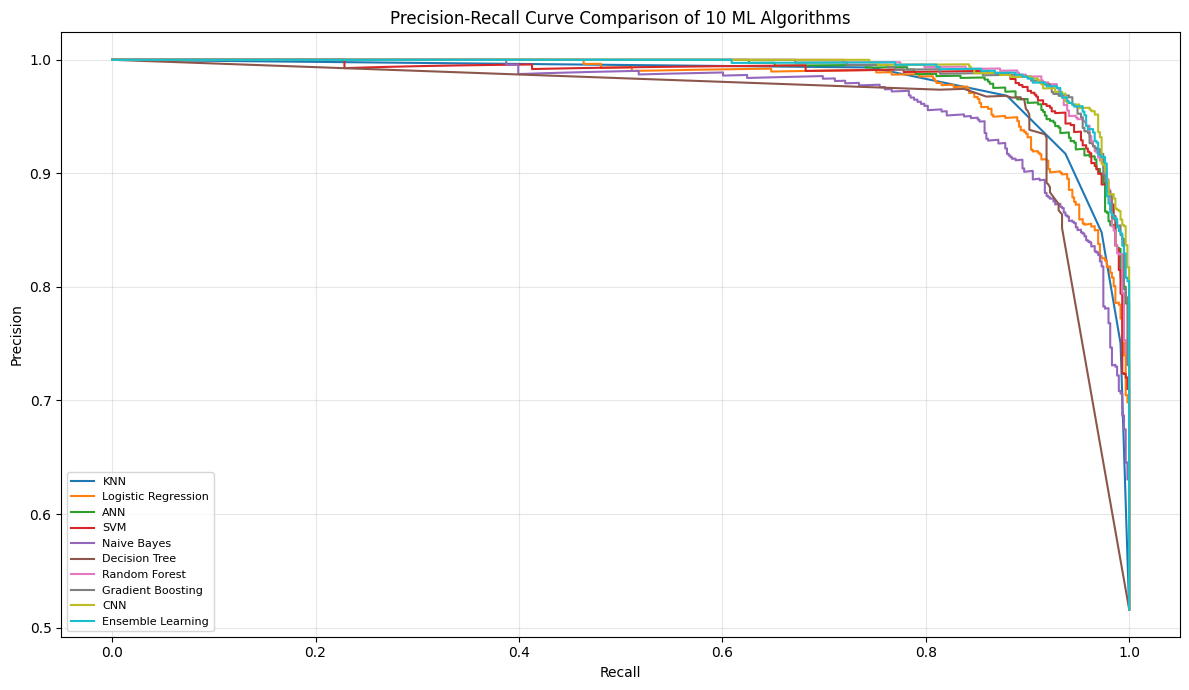

In [ ]:
# PRECISION-RECALL CURVE COMPARISON OF 10 ML ALGORITHMS

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

# Create dictionary of all 10 trained models
pr_models = {
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "ANN": ann_model,
    "SVM": svm_model,
    "Naive Bayes": nb_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "CNN": cnn_model,
    "Ensemble Learning": ensemble_model
}

# Convert actual test values into array
y_true = np.asarray(y_test).ravel()

# Create figure
plt.figure(figsize=(12, 7))

# Generate Precision-Recall curves
for name, model in pr_models.items():

    # CNN uses separate 3D test data
    if name == "CNN":
        y_scores = cnn_model.predict(X_test_cnn, verbose=0).ravel()

    # Other models use scaled 2D test data
    elif hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test_scaled)

        if y_scores.ndim == 2:
            y_scores = y_scores[:, 1]

    elif hasattr(model, "decision_function"):
        y_scores = model.decision_function(X_test_scaled)

    else:
        print(name, "does not support score-based PR curve.")
        continue

    # Calculate precision and recall
    precision, recall, thresholds = precision_recall_curve(
        y_true, y_scores, pos_label=1
    )

    # Plot curve
    plt.plot(recall, precision, label=name)

# Graph formatting
plt.title("Precision-Recall Curve Comparison of 10 ML Algorithms")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Check CNN input dimensions

print("CNN MODEL INPUT SHAPE:")
print(cnn_model.input_shape)

print("\nTEST DATA TYPE:")
print(type(X_test_scaled))

print("\nTEST DATA SHAPE:")
print(np.asarray(X_test_scaled).shape)

print("\nCNN MODEL OUTPUT SHAPE:")
print(cnn_model.output_shape)

CNN MODEL INPUT SHAPE:
(None, 30, 1)

TEST DATA TYPE:
<class 'numpy.ndarray'>

TEST DATA SHAPE:
(1145, 30)

CNN MODEL OUTPUT SHAPE:
(None, 1)


In [ ]:
print("CNN TEST DATA SHAPE:")
print(X_test_cnn.shape)

print("\nCNN TRAINING DATA SHAPE:")
print(X_train_cnn.shape)

CNN TEST DATA SHAPE:
(1145, 30, 1)

CNN TRAINING DATA SHAPE:
(4576, 30, 1)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


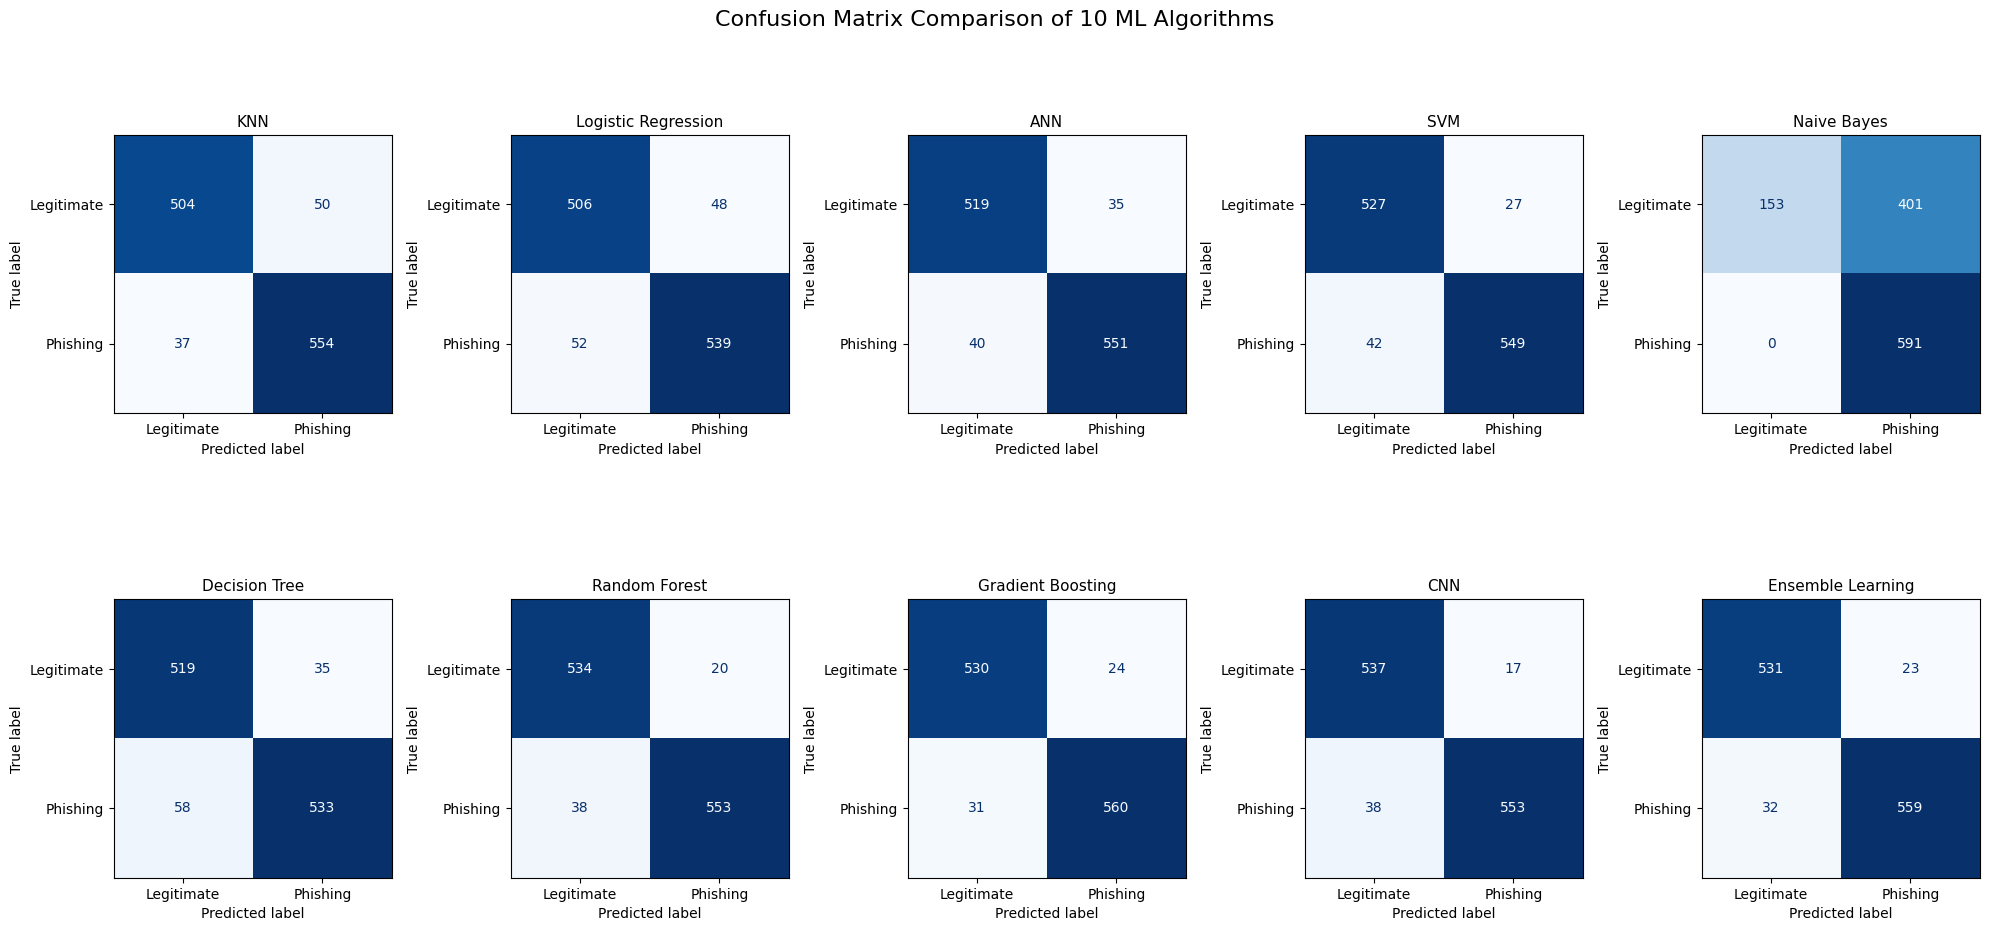

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Actual target values
y_true = np.asarray(y_test).ravel()

# Prepare test data for CNN
x_test_cnn = np.asarray(X_test_scaled).reshape(-1, 30, 1)

# Create figure
fig, axes = plt.subplots(2, 5, figsize=(20, 10))
axes = axes.flatten()

# Compare all 10 algorithms
for i, (name, model) in enumerate(models.items()):

    # Generate predictions
    if name.lower() == "cnn":
        cnn_probabilities = cnn_model.predict(
            x_test_cnn, verbose=0
        ).ravel()

        y_pred = (cnn_probabilities >= 0.5).astype(int)

    else:
        y_pred = np.asarray(
            model.predict(X_test_scaled)
        ).ravel()

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    )

    # Display confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Phishing"]
    )

    disp.plot(
        ax=axes[i],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axes[i].set_title(name, fontsize=11)

plt.suptitle(
    "Confusion Matrix Comparison of 10 ML Algorithms",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

classification_results = []

for name, model in models.items():

    # CNN predictions
    if name.lower() == "cnn":
        probabilities = cnn_model.predict(x_test_cnn, verbose=0).ravel()
        y_pred = (probabilities >= 0.5).astype(int)

    else:
        y_pred = model.predict(X_test_scaled)

    y_pred = np.asarray(y_pred).ravel()

    # Calculate evaluation metrics
    classification_results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0)
    })

# Create comparison table
classification_df = pd.DataFrame(classification_results)

print("CLASSIFICATION REPORT COMPARISON")
display(classification_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


CLASSIFICATION REPORT COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,KNN,0.9240,0.9172,0.9374,0.9272
1,Logistic Regression,0.9127,0.9182,0.9120,0.9151
2,ANN,0.9345,0.9403,0.9323,0.9363
3,SVM,0.9397,0.9531,0.9289,0.9409
4,Naive Bayes,0.6498,0.5958,1.0000,0.7467
5,Decision Tree,0.9188,0.9384,0.9019,0.9198
6,Random Forest,0.9493,0.9651,0.9357,0.9502
7,Gradient Boosting,0.9520,0.9589,0.9475,0.9532
8,CNN,0.9520,0.9702,0.9357,0.9526
9,Ensemble Learning,0.9520,0.9605,0.9459,0.9531


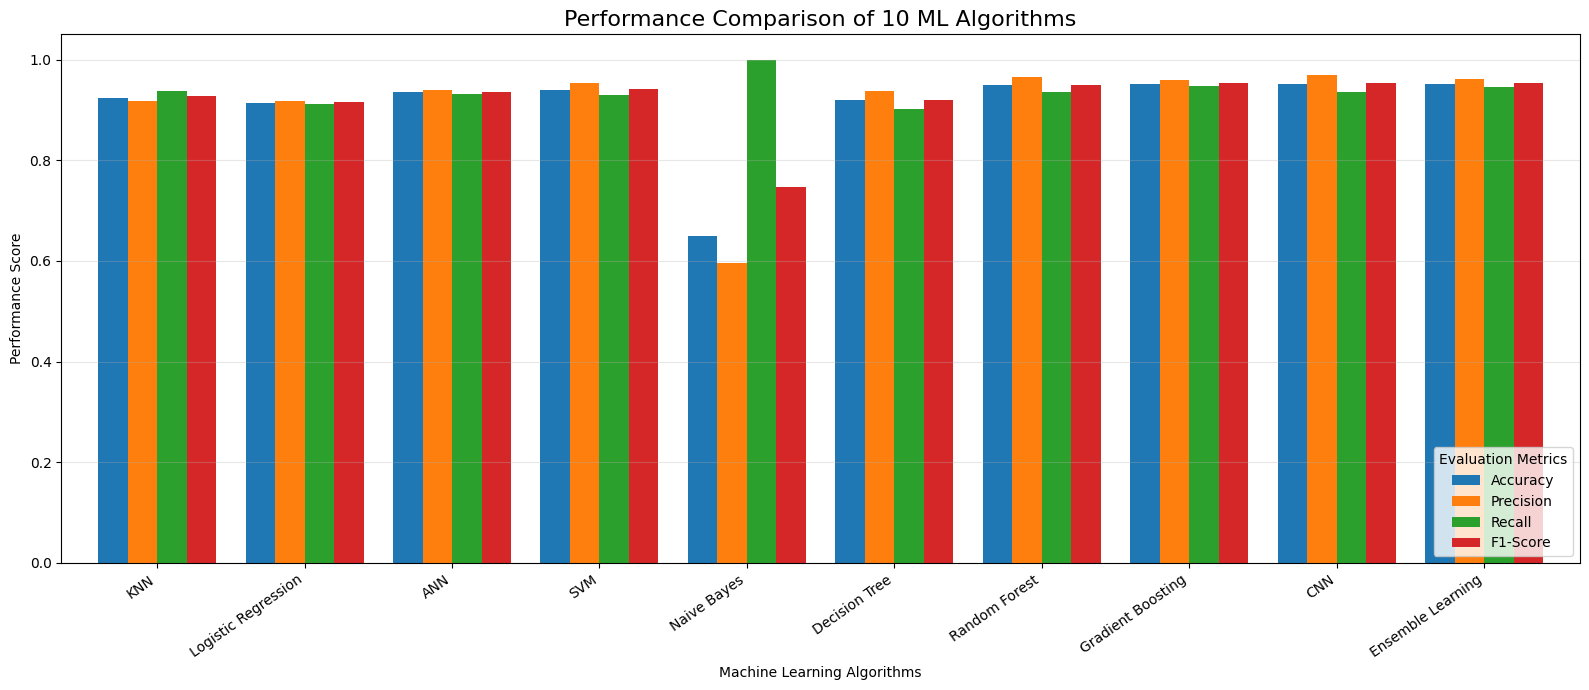

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

classification_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title(
    "Performance Comparison of 10 ML Algorithms",
    fontsize=16
)

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=35, ha="right")

plt.legend(
    title="Evaluation Metrics",
    loc="lower right"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
import pandas as pd
import numpy as np

roc_results = []

for name, model in models.items():

    if name.lower() == "cnn":
        y_scores = cnn_model.predict(
            x_test_cnn, verbose=0
        ).ravel()

    elif hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(
            X_test_scaled
        )[:, 1]

    elif hasattr(model, "decision_function"):
        y_scores = model.decision_function(
            X_test_scaled
        )

    else:
        y_scores = model.predict(X_test_scaled)

    auc = roc_auc_score(y_true, y_scores)

    roc_results.append({
        "Algorithm": name,
        "ROC-AUC Score": auc
    })

roc_df = pd.DataFrame(roc_results)

roc_df = roc_df.sort_values(
    by="ROC-AUC Score",
    ascending=False
)

print("ROC-AUC COMPARISON OF 10 ML ALGORITHMS")

display(roc_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


ROC-AUC COMPARISON OF 10 ML ALGORITHMS


,Algorithm,ROC-AUC Score
8,CNN,0.9922
9,Ensemble Learning,0.9912
7,Gradient Boosting,0.9903
6,Random Forest,0.9903
2,ANN,0.9868
3,SVM,0.9860
1,Logistic Regression,0.9771
0,KNN,0.9765
4,Naive Bayes,0.9673
5,Decision Tree,0.9460


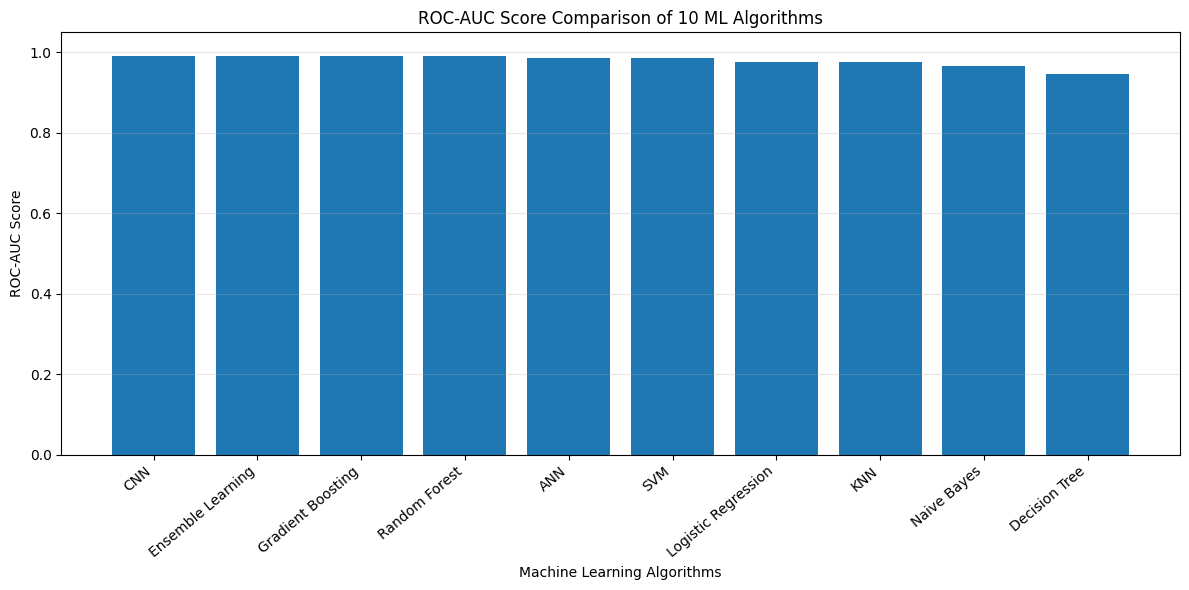

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    roc_df["Algorithm"],
    roc_df["ROC-AUC Score"]
)

plt.title("ROC-AUC Score Comparison of 10 ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("ROC-AUC Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=40, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Select the best-performing ML algorithm

results_df = pd.DataFrame(results).T

best_algorithm = results_df["F1-Score"].idxmax()
best_f1_score = results_df["F1-Score"].max()

print("BEST PERFORMING ALGORITHM")
print("--------------------------")
print("Algorithm:", best_algorithm)
print("F1-Score:", round(best_f1_score, 4))

print("\nComplete Algorithm Ranking:")
display(results_df.sort_values(
    by="F1-Score", ascending=False
))

BEST PERFORMING ALGORITHM
--------------------------
Algorithm: Gradient Boosting
F1-Score: 0.954

Complete Algorithm Ranking:


,Accuracy,Precision,Recall,F1-Score
Gradient Boosting,0.952838,0.960549,0.947547,0.954003
Ensemble Learning,0.951965,0.960481,0.945854,0.953112
Random Forest,0.951965,0.966899,0.939086,0.952790
CNN,0.951965,0.970175,0.935702,0.952627
Decision Tree,0.939738,0.942373,0.940778,0.941575
SVM,0.939738,0.953125,0.928934,0.940874
ANN,0.934498,0.940273,0.932318,0.936279
KNN,0.924017,0.917219,0.937394,0.927197
Logistic Regression,0.912664,0.918228,0.912014,0.915110
Naive Bayes,0.649782,0.595766,1.000000,0.746684


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


GRADIENT BOOSTING - FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       554
           1       0.96      0.95      0.95       591

    accuracy                           0.95      1145
   macro avg       0.95      0.95      0.95      1145
weighted avg       0.95      0.95      0.95      1145



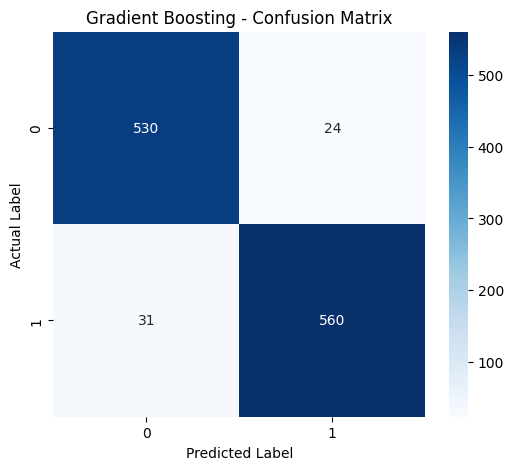

In [ ]:
# Final evaluation of Gradient Boosting

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions
y_pred_final = gb_model.predict(X_test_scaled)

# Classification report
print("GRADIENT BOOSTING - FINAL CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_final))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
# Save the best-performing Gradient Boosting model

import joblib

joblib.dump(gb_model, "best_phishing_detection_model.pkl")

print("Gradient Boosting model saved successfully!")

Gradient Boosting model saved successfully!


In [ ]:
# Save the StandardScaler

import joblib

joblib.dump(scaler, "standard_scaler.pkl")

print("StandardScaler saved successfully!")

StandardScaler saved successfully!


In [ ]:
from google.colab import files

files.download("best_phishing_detection_model.pkl")
files.download("standard_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Load the saved model and scaler

import joblib

# Load Gradient Boosting model
loaded_model = joblib.load("best_phishing_detection_model.pkl")

# Load StandardScaler
loaded_scaler = joblib.load("standard_scaler.pkl")

print("Model loaded successfully!")
print("Scaler loaded successfully!")

print("\nModel:", type(loaded_model).__name__)
print("Scaler:", type(loaded_scaler).__name__)

Model loaded successfully!
Scaler loaded successfully!

Model: GradientBoostingClassifier
Scaler: StandardScaler


In [ ]:
# Test the saved model using real test data

import numpy as np

# Select one website from the test dataset
sample_data = x_test_scaled[0].reshape(1, -1)

# Predict using the saved model
prediction = loaded_model.predict(sample_data)[0]

# Get actual result
actual = np.asarray(y_test).ravel()[0]

# Display prediction
print("WEBSITE PHISHING DETECTION RESULT")
print("----------------------------------")

if prediction == 1:
    print("Predicted Result: PHISHING WEBSITE")
else:
    print("Predicted Result: LEGITIMATE WEBSITE")

print("Actual Result:", actual)

if prediction == actual:
    print("Prediction Status: CORRECT")
else:
    print("Prediction Status: INCORRECT")

NameError: name 'x_test_scaled' is not defined

In [ ]:
# Check which variables are available

print("x_test exists:", 'x_test' in globals())
print("y_test exists:", 'y_test' in globals())
print("x_test_scaled exists:", 'x_test_scaled' in globals())
print("x_train exists:", 'x_train' in globals())
print("df exists:", 'df' in globals())

x_test exists: False
y_test exists: True
x_test_scaled exists: False
x_train exists: False
df exists: True


In [ ]:
# Check dataset before restoring test variables

print("Dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nTarget column values:")
print(df["Result"].value_counts())

print("\nExisting y_test shape:")
print(y_test.shape)

Dataset shape: (11055, 31)

Dataset columns:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']

Target column values:
Result
1     6157
-1    4898
Name: count, dtype: int64

Existing y_test shape:
(1145,)


In [ ]:
# Check the saved scaler and existing test labels

print("Y_TEST type:", type(y_test))
print("Y_TEST index:", y_test.index[:10])

print("\nScaler features:")
print(loaded_scaler.n_features_in_)

print("\nScaler feature names:")
print(getattr(loaded_scaler, "feature_names_in_", "Not available"))

Y_TEST type: <class 'pandas.core.series.Series'>
Y_TEST index: Index([1443, 10094, 6582, 9646, 1521, 9916, 8656, 1081, 7301, 6357], dtype='int64')

Scaler features:
30

Scaler feature names:
['having_IP_Address' 'URL_Length' 'Shortining_Service' 'having_At_Symbol'
 'double_slash_redirecting' 'Prefix_Suffix' 'having_Sub_Domain'
 'SSLfinal_State' 'Domain_registeration_length' 'Favicon' 'port'
 'HTTPS_token' 'Request_URL' 'URL_of_Anchor' 'Links_in_tags' 'SFH'
 'Submitting_to_email' 'Abnormal_URL' 'Redirect' 'on_mouseover'
 'RightClick' 'popUpWidnow' 'Iframe' 'age_of_domain' 'DNSRecord'
 'web_traffic' 'Page_Rank' 'Google_Index' 'Links_pointing_to_page'
 'Statistical_report']


In [ ]:
# Reconstruct missing test data

# Get the original 30 feature columns
feature_columns = loaded_scaler.feature_names_in_

# Reconstruct X_test using existing test indices
x_test = df.loc[y_test.index, feature_columns].copy()

# Scale the test data using the saved scaler
x_test_scaled = loaded_scaler.transform(x_test)

# Display results
print("X_test restored successfully!")
print("X_test shape:", x_test.shape)

print("\nScaled test data restored successfully!")
print("X_test_scaled shape:", x_test_scaled.shape)

print("\nY_test shape:", y_test.shape)

# Verify dimensions
assert x_test.shape[1] == 30
assert x_test_scaled.shape[1] == 30
assert len(x_test) == len(y_test)

print("\nAll dimensions verified successfully!")

X_test restored successfully!
X_test shape: (1145, 30)

Scaled test data restored successfully!
X_test_scaled shape: (1145, 30)

Y_test shape: (1145,)

All dimensions verified successfully!


In [ ]:
# Test the saved Gradient Boosting model

# Select one website from the test dataset
sample_data = x_test_scaled[0].reshape(1, -1)

# Predict using the loaded model
prediction = loaded_model.predict(sample_data)[0]

# Get actual result
actual = y_test.iloc[0]

print("Predicted Value:", prediction)
print("Actual Value:", actual)

if prediction == actual:
    print("Prediction Status: CORRECT")
else:
    print("Prediction Status: INCORRECT")

Predicted Value: 1
Actual Value: 0
Prediction Status: INCORRECT


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Predict all test samples
y_pred = loaded_model.predict(x_test_scaled)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print("MODEL TESTING RESULTS")
print("----------------------")
print("Total test samples:", len(y_test))
print("Correct predictions:", sum(y_test == y_pred))
print("Incorrect predictions:", sum(y_test != y_pred))
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

MODEL TESTING RESULTS
----------------------
Total test samples: 1145
Correct predictions: 559
Incorrect predictions: 586
Testing Accuracy: 48.82 %

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.56      0.51       554
           1       0.51      0.42      0.46       591

    accuracy                           0.49      1145
   macro avg       0.49      0.49      0.49      1145
weighted avg       0.49      0.49      0.49      1145



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


In [ ]:
print("TEST DATA CHECK")
print("----------------")

print("X test shape:", x_test.shape)
print("Scaled test shape:", x_test_scaled.shape)
print("Y test shape:", y_test.shape)

print("\nActual class distribution:")
print(y_test.value_counts())

print("\nPredicted class distribution:")
print(pd.Series(y_pred).value_counts())

print("\nFirst 10 actual labels:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())

print("\nScaler feature count:", loaded_scaler.n_features_in_)
print("Model feature count:", loaded_model.n_features_in_)

TEST DATA CHECK
----------------
X test shape: (1145, 30)
Scaled test shape: (1145, 30)
Y test shape: (1145,)

Actual class distribution:
Result
1    591
0    554
Name: count, dtype: int64

Predicted class distribution:
0    648
1    497
Name: count, dtype: int64

First 10 actual labels:
[0, 1, 1, 1, 0, 1, 0, 0, 1, 1]

First 10 predicted labels:
[1, 1, 0, 0, 1, 0, 1, 0, 0, 0]

Scaler feature count: 30
Model feature count: 30


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX:")
print(cm)

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

print("\nFIRST 20 TEST INDICES:")
print(y_test.index[:20].tolist())

print("\nFIRST 20 DATASET INDICES:")
print(x_test.index[:20].tolist())

CONFUSION MATRIX:
[[308 246]
 [340 251]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.48      0.56      0.51       554
           1       0.51      0.42      0.46       591

    accuracy                           0.49      1145
   macro avg       0.49      0.49      0.49      1145
weighted avg       0.49      0.49      0.49      1145


FIRST 20 TEST INDICES:
[1443, 10094, 6582, 9646, 1521, 9916, 8656, 1081, 7301, 6357, 5795, 934, 752, 2452, 5709, 9405, 966, 6539, 2953, 10391]

FIRST 20 DATASET INDICES:
[1443, 10094, 6582, 9646, 1521, 9916, 8656, 1081, 7301, 6357, 5795, 934, 752, 2452, 5709, 9405, 966, 6539, 2953, 10391]


In [ ]:
print("TRAINING DATA SHAPE:", X_train.shape)
print("TEST DATA SHAPE:", x_test.shape)

print("\nTRAINING LABEL DISTRIBUTION:")
print(y_train.value_counts())

print("\nTEST LABEL DISTRIBUTION:")
print(y_test.value_counts())

print("\nMODEL TYPE:", type(loaded_model).__name__)
print("SCALER TYPE:", type(loaded_scaler).__name__)

TRAINING DATA SHAPE: (4576, 30)
TEST DATA SHAPE: (1145, 30)

TRAINING LABEL DISTRIBUTION:
Result
1    2364
0    2212
Name: count, dtype: int64

TEST LABEL DISTRIBUTION:
Result
1    591
0    554
Name: count, dtype: int64

MODEL TYPE: GradientBoostingClassifier
SCALER TYPE: StandardScaler


In [ ]:
print("ORIGINAL MODEL ACCURACY:")
print(accuracy_score(y_test, gb_model.predict(X_test_scaled)))

print("\nLOADED MODEL ACCURACY:")
print(accuracy_score(y_test, loaded_model.predict(x_test_scaled)))

print("\nORIGINAL AND LOADED MODEL PREDICTIONS:")
print((gb_model.predict(X_test_scaled) == loaded_model.predict(x_test_scaled)).all())

ORIGINAL MODEL ACCURACY:
0.9519650655021834

LOADED MODEL ACCURACY:
0.4882096069868996

ORIGINAL AND LOADED MODEL PREDICTIONS:
False


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


In [ ]:
original_predictions = gb_model.predict(X_test_scaled)
loaded_predictions = loaded_model.predict(x_test_scaled)

print("Original model predictions:")
print(original_predictions[:20])

print("\nLoaded model predictions:")
print(loaded_predictions[:20])

print("\nAre predictions identical?")
print((original_predictions == loaded_predictions).all())

print("\nOriginal model parameters:")
print(gb_model.get_params())

print("\nLoaded model parameters:")
print(loaded_model.get_params())

Original model predictions:
[1 1 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 1 1 0]

Loaded model predictions:
[1 1 0 0 1 0 1 0 0 0 1 1 0 0 1 0 0 0 0 0]

Are predictions identical?
False

Original model parameters:
{'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}

Loaded model parameters:
{'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_sta

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


In [ ]:
import numpy as np

print("ORIGINAL TEST DATA:")
print(X_test_scaled[:5])

print("\nRECONSTRUCTED TEST DATA:")
print(x_test_scaled[:5])

print("\nAre both test datasets identical?")
print(np.allclose(X_test_scaled, x_test_scaled))

print("\nMaximum difference:")
print(np.max(np.abs(X_test_scaled - x_test_scaled)))

ORIGINAL TEST DATA:
[[ 0.87177979 -0.49732563  0.40798804  0.51457475  0.40980828 -0.37569553
  -1.31852773 -1.23827456 -0.7304191  -1.92305797 -2.23724146  0.46272578
   0.88426889  0.19426737 -1.10912901 -0.55884062 -1.89103146  0.43992222
  -0.39956895  0.40835237  0.23266928 -1.86951555  0.35416154  0.9783805
   0.6076512   0.92313797 -0.63807058 -2.19587863 -0.59153025  0.42389325]
 [-1.14707867 -0.49732563  0.40798804  0.51457475  0.40980828 -0.37569553
  -1.31852773 -0.15752987  1.36907701  0.52000513  0.44697902  0.46272578
   0.88426889 -1.17548221 -1.10912901 -0.55884062  0.52881193  0.43992222
  -0.39956895  0.40835237  0.23266928  0.53489793  0.35416154  0.9783805
   0.6076512  -0.28207725 -0.63807058  0.45539858  1.12600936  0.42389325]
 [-1.14707867 -0.49732563  0.40798804  0.51457475  0.40980828 -0.37569553
  -0.07807072 -1.23827456 -0.7304191   0.52000513  0.44697902  0.46272578
  -1.13087774 -1.17548221  0.1849491  -0.55884062  0.52881193  0.43992222
  -0.39956895  0.4

In [ ]:
print("ORIGINAL X_TEST:")
print(X_test.head())

print("\nRECONSTRUCTED X_TEST:")
print(x_test.head())

print("\nORIGINAL TEST INDEX:")
print(X_test.index[:10].tolist())

print("\nRECONSTRUCTED TEST INDEX:")
print(x_test.index[:10].tolist())

print("\nORIGINAL SCALED SHAPE:", X_test_scaled.shape)
print("RECONSTRUCTED SCALED SHAPE:", x_test_scaled.shape)

ORIGINAL X_TEST:
       having_IP_Address  URL_Length  Shortining_Service  having_At_Symbol  \
1443                   1          -1                   1                 1   
10094                 -1          -1                   1                 1   
6582                  -1          -1                   1                 1   
9646                  -1           1                  -1                -1   
1521                   1          -1                   1                 1   

       double_slash_redirecting  Prefix_Suffix  having_Sub_Domain  \
1443                          1             -1                 -1   
10094                         1             -1                 -1   
6582                          1             -1                  0   
9646                         -1             -1                 -1   
1521                          1             -1                  0   

       SSLfinal_State  Domain_registeration_length  Favicon  ...  RightClick  \
1443               

In [ ]:
import numpy as np

print("Original test data available:", X_test_scaled.shape)
print("Original model available:", type(gb_model).__name__)

# Save the original model and scaler again
import joblib

joblib.dump(gb_model, "best_phishing_detection_model.pkl")
joblib.dump(scaler, "standard_scaler.pkl")

print("\nOriginal model and scaler saved again!")

Original test data available: (1145, 30)
Original model available: GradientBoostingClassifier

Original model and scaler saved again!


In [ ]:
from google.colab import files

files.download("best_phishing_detection_model.pkl")
files.download("standard_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import accuracy_score

final_predictions = gb_model.predict(X_test_scaled)

print("FINAL MODEL VERIFICATION")
print("------------------------")
print("Total test samples:", len(y_test))
print("Correct predictions:", sum(y_test.to_numpy() == final_predictions))
print("Incorrect predictions:", sum(y_test.to_numpy() != final_predictions))
print("Final accuracy:", round(accuracy_score(y_test, final_predictions) * 100, 2), "%")

FINAL MODEL VERIFICATION
------------------------
Total test samples: 1145
Correct predictions: 1090
Incorrect predictions: 55
Final accuracy: 95.2 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
